# NSD: exploration

Optional. Quick ECDFs straight from the MySQL import; nothing else depends on this notebook.

# ECDF of return_time - invoke_time
Connect to local MySQL and plot an aggregated ECDF plus per-`size` ECDFs. Update `database` and `table_name` if needed.

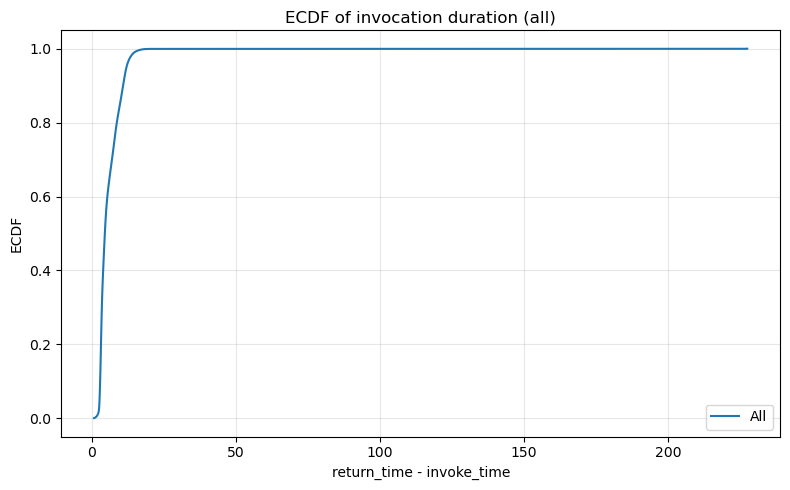

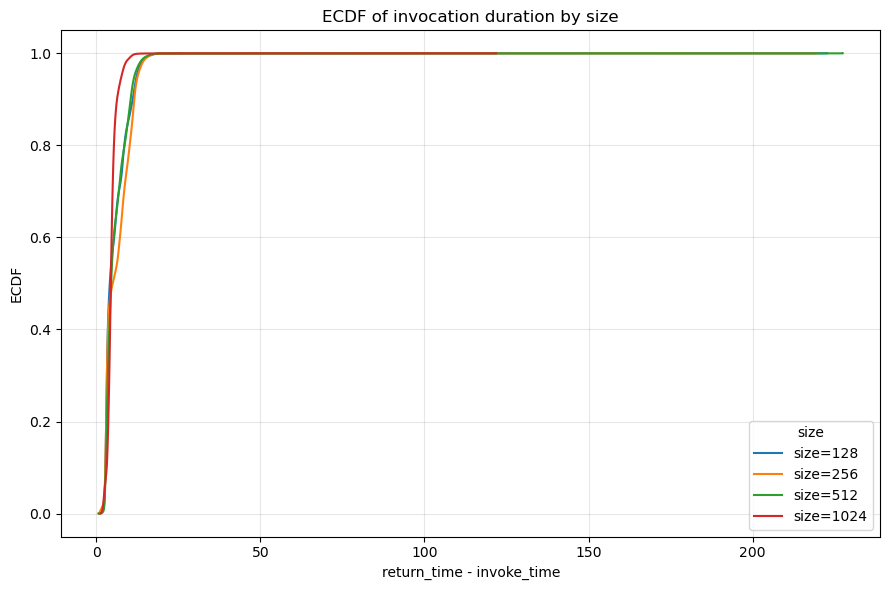

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

database = "benchmark"
table_name = "data"

engine = create_engine(f"mysql+pymysql://root:@localhost/{database}")

df = pd.read_sql(f"SELECT invoke_time, return_time, size FROM {table_name}", engine)

df["duration"] = df["return_time"] - df["invoke_time"]
df = df.dropna(subset=["duration"])

def ecdf(values):
    values = np.sort(values)
    y = np.arange(1, len(values) + 1) / len(values)
    return values, y

# Aggregated ECDF
x_all, y_all = ecdf(df["duration"].to_numpy())
plt.figure(figsize=(8, 5))
plt.step(x_all, y_all, where="post", label="All")
plt.xlabel("return_time - invoke_time")
plt.ylabel("ECDF")
plt.title("ECDF of invocation duration (all)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ECDF by size
plt.figure(figsize=(9, 6))
for size in sorted(df["size"].dropna().unique()):
    x_s, y_s = ecdf(df.loc[df["size"] == size, "duration"].to_numpy())
    plt.step(x_s, y_s, where="post", label=f"size={size}")
plt.xlabel("return_time - invoke_time")
plt.ylabel("ECDF")
plt.title("ECDF of invocation duration by size")
plt.grid(True, alpha=0.3)
plt.legend(title="size")
plt.tight_layout()
plt.show()

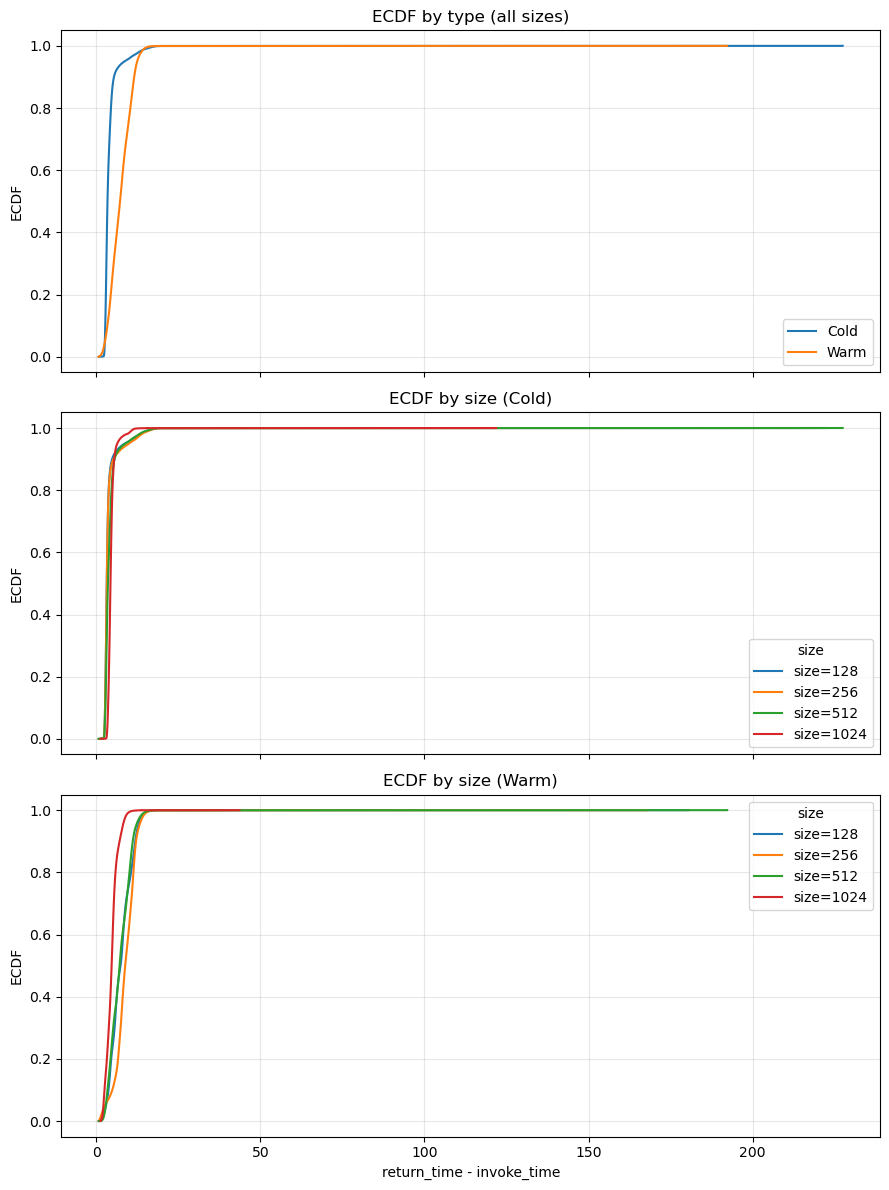

In [14]:
# Cold vs warm ECDFs (aggregated + per-size)
df2 = pd.read_sql(f"SELECT invoke_time, return_time, size, type FROM {table_name}", engine)
df2["duration"] = df2["return_time"] - df2["invoke_time"]
df2 = df2.dropna(subset=["duration", "type"])

fig, axes = plt.subplots(3, 1, figsize=(9, 12), sharex=True)

# Aggregated ECDF with cold/warm in same subplot
ax0 = axes[0]
for label in ["Cold", "Warm"]:
    vals = df2.loc[df2["type"] == label, "duration"].to_numpy()
    if len(vals) == 0:
        continue
    x, y = ecdf(vals)
    ax0.step(x, y, where="post", label=label)
ax0.set_ylabel("ECDF")
ax0.set_title("ECDF by type (all sizes)")
ax0.grid(True, alpha=0.3)
ax0.legend()

# Per-size ECDFs for cold and warm in separate subplots
for ax, label in zip(axes[1:], ["Cold", "Warm"]):
    subset = df2.loc[df2["type"] == label]
    for size in sorted(subset["size"].dropna().unique()):
        vals = subset.loc[subset["size"] == size, "duration"].to_numpy()
        if len(vals) == 0:
            continue
        x, y = ecdf(vals)
        ax.step(x, y, where="post", label=f"size={size}")
    ax.set_ylabel("ECDF")
    ax.set_title(f"ECDF by size ({label})")
    ax.grid(True, alpha=0.3)
    ax.legend(title="size")

axes[-1].set_xlabel("return_time - invoke_time")
plt.tight_layout()
plt.show()

Warm-only duration stats (return_time - invoke_time)
Total warm values: 1106933
p95: threshold=12.447995, mean_all/mean_cropped=1.0491, <=p95=1051586, >p95=55347
p99: threshold=14.496775, mean_all/mean_cropped=1.0129, <=p99=1095863, >p99=11070
p99.9: threshold=17.059751, mean_all/mean_cropped=1.0029, <=p99.9=1105826, >p99.9=1107
p99.99: threshold=48.052084, mean_all/mean_cropped=1.0013, <=p99.99=1106822, >p99.99=111


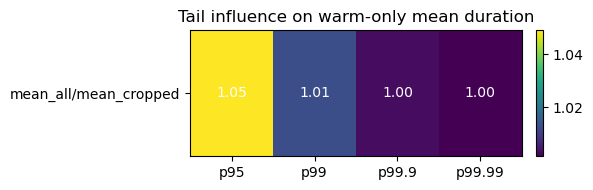

In [ ]:
# Heatmap: tail influence on warm-only durations
df3 = pd.read_sql(f"SELECT invoke_time, return_time, size, type, isCold FROM {table_name}", engine)
df3["duration"] = df3["return_time"] - df3["invoke_time"]
df3 = df3.dropna(subset=["duration"])

is_cold_raw = df3["isCold"].astype(str).str.lower()
warm_mask = (is_cold_raw.isin(["false", "0", "no"])) | (df3["type"].astype(str).str.lower() == "warm")
warm = df3.loc[warm_mask, "duration"].dropna()

percentiles = [95, 99, 99.9, 99.99]
p_values = np.percentile(warm.to_numpy(), percentiles)
median = float(np.median(warm.to_numpy()))
if not np.isfinite(median) or median <= 0:
    raise ValueError(f"Invalid median warm duration: {median}")

factors = []
counts = []
for p, v in zip(percentiles, p_values):
    factor = (v / median) if np.isfinite(v) else np.nan
    factors.append(factor)
    counts.append((int((warm <= v).sum()), int((warm > v).sum())))

print("Warm-only duration stats (return_time - invoke_time)")
print(f"Total warm values: {len(warm)}")
print(f"Median warm duration: {median:.6f}")
for p, v, f, (n_in, n_tail) in zip(percentiles, p_values, factors, counts):
    print(f"p{p}: value={v:.6f}, p{p}/median={f:.4f}, <=p{p}={n_in}, >p{p}={n_tail}")

fig, ax = plt.subplots(figsize=(6, 2))
heat = np.array([factors])
im = ax.imshow(heat, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(percentiles)))
ax.set_xticklabels([f"p{p}" for p in percentiles])
ax.set_yticks([0])
ax.set_yticklabels(["pXX/median"])
for j, val in enumerate(factors):
    ax.text(j, 0, f"{val:.2f}", ha="center", va="center", color="white")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.title("Warm-only tail factor: percentile / median")
plt.tight_layout()
plt.show()

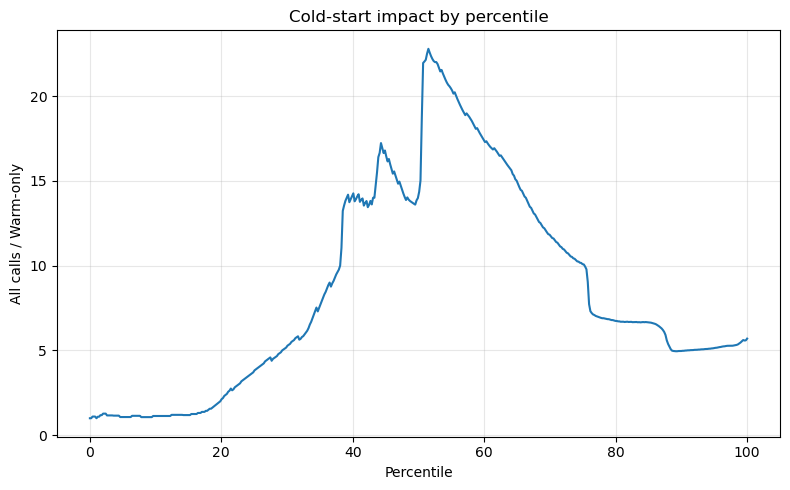

In [7]:
# Percentile ratio: all calls vs warm-only
df4 = pd.read_sql(f"SELECT google_time, isCold FROM {table_name}", engine)
df4["duration"] = df4["google_time"]
df4 = df4.dropna(subset=["duration"])

is_cold_raw = df4["isCold"].astype(str).str.lower()
warm_mask = (is_cold_raw.isin(["false", "0", "no"])) 
dur_all = df4["duration"].to_numpy()
dur_warm = df4.loc[warm_mask, "duration"].to_numpy()

percentile_grid = np.linspace(0, 100, 500)
q_all = np.percentile(dur_all, percentile_grid)
q_warm = np.percentile(dur_warm, percentile_grid)
ratio = q_all / q_warm

plt.figure(figsize=(8, 5))
plt.plot(percentile_grid, ratio)
plt.xlabel("Percentile")
plt.ylabel("All calls / Warm-only")
plt.title("Cold-start impact by percentile")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

    hour    count   p50    p95     p99     p99.9     p99.99    p50_n    p95_n  \
0      0  42659.0  51.0  626.0  717.00  1090.052  3192.7316  21345.0  19194.0   
1      1  43331.0  42.0  619.0  710.00  1041.350  2473.7170  21773.0  19419.0   
2      2  43429.0  42.0  614.0  705.00   941.288  2281.8680  21742.0  19531.0   
3      3  43699.0  41.0  614.0  703.02   971.604  2070.1710  21883.0  19634.0   
4      4  43486.0  43.0  613.0  704.00   980.030  2402.5285  21829.0  19518.0   
5      5  43585.0  45.0  614.0  704.00   943.160  2407.4208  21872.0  19551.0   
6      6  42668.0  49.0  620.0  712.00   970.333  2099.5304  21343.0  19241.0   
7      7  41702.0  54.0  622.0  716.99  1121.299  2167.5003  20901.0  18717.0   
8      8  39650.0  59.0  621.0  714.00   959.351  1978.0049  19836.0  17854.0   
9      9  39086.0  59.0  622.0  712.00   924.660  2469.9215  19597.0  17539.0   
10    10  37744.0  59.0  622.0  721.57  1045.827  2657.9967  18934.0  16938.0   
11    11  37746.0  62.0  624

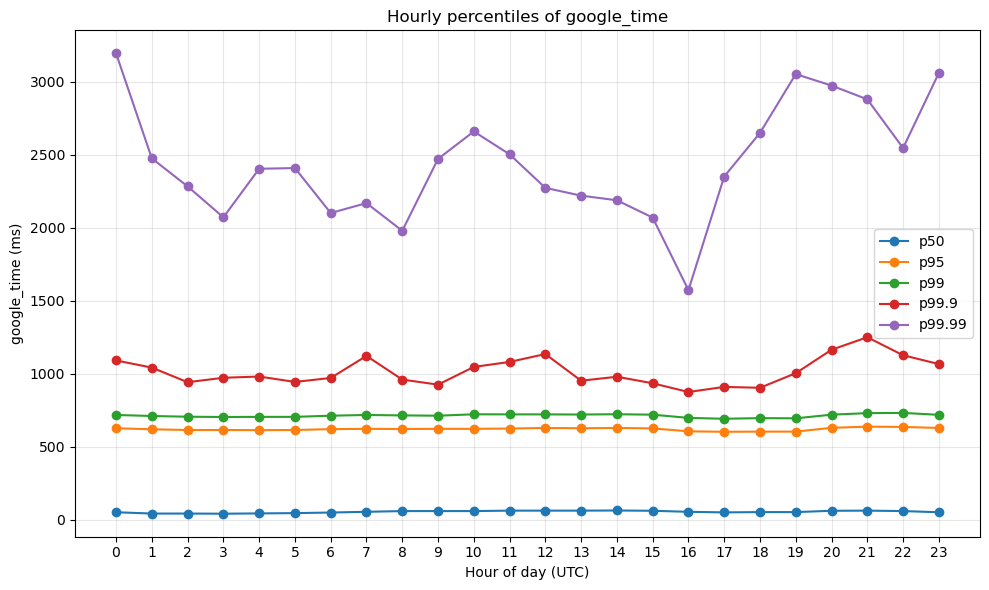

In [4]:
# Hourly percentile buckets for google_time by invoke_time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hourly_df = pd.read_sql(
    f"SELECT google_time, invoke_time FROM {table_name} WHERE isCold = 'False'",
    engine,
)
hourly_df = hourly_df.dropna(subset=["google_time", "invoke_time"]).copy()

# invoke_time is seconds with fractional part; google_time is ms
hourly_df["invoke_dt"] = pd.to_datetime(hourly_df["invoke_time"], unit="s", utc=True)
hourly_df["hour"] = hourly_df["invoke_dt"].dt.hour

percentiles = [50, 95, 99, 99.9, 99.99]

def percentile_summary(values: pd.Series) -> pd.Series:
    values = values.to_numpy()
    if len(values) == 0:
        data = {f"p{p}": np.nan for p in percentiles}
        data.update({f"p{p}_n": 0 for p in percentiles})
        data["count"] = 0
        return pd.Series(data)

    p_vals = [np.percentile(values, p) for p in percentiles]
    n_le = [int((values <= v).sum()) for v in p_vals]
    n_bucket = []
    prev = 0
    for n in n_le:
        n_bucket.append(n - prev)
        prev = n

    data = {f"p{p}": v for p, v in zip(percentiles, p_vals)}
    data.update({f"p{p}_n": n for p, n in zip(percentiles, n_bucket)})
    data["count"] = len(values)
    return pd.Series(data)

summary = (
    hourly_df.groupby("hour")["google_time"]
    .apply(percentile_summary)
    .unstack()
    .sort_index()
    .reset_index()
)

print(summary[["hour", "count"] + [f"p{p}" for p in percentiles] + [f"p{p}_n" for p in percentiles]])

plt.figure(figsize=(10, 6))
for p in percentiles:
    plt.plot(summary["hour"], summary[f"p{p}"], marker="o", label=f"p{p}")

plt.xlabel("Hour of day (UTC)")
plt.ylabel("google_time (ms)")
plt.title("Hourly percentiles of google_time")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()